DATASET LOADED SUCCESSFULLY

FIRST 5 ROWS:
   symboling  normalized-losses         make fuel-type aspiration  \
0          3                NaN  alfa-romero       gas        std   
1          3                NaN  alfa-romero       gas        std   
2          1                NaN  alfa-romero       gas        std   
3          2              164.0         audi       gas        std   
4          2              164.0         audi       gas        std   

  num-of-doors   body-style drive-wheels engine-location  wheel-base  ...  \
0          two  convertible          rwd           front        88.6  ...   
1          two  convertible          rwd           front        88.6  ...   
2          two    hatchback          rwd           front        94.5  ...   
3         four        sedan          fwd           front        99.8  ...   
4         four        sedan          4wd           front        99.4  ...   

   engine-size  fuel-system  bore  stroke compression-ratio horsepower  \
0    

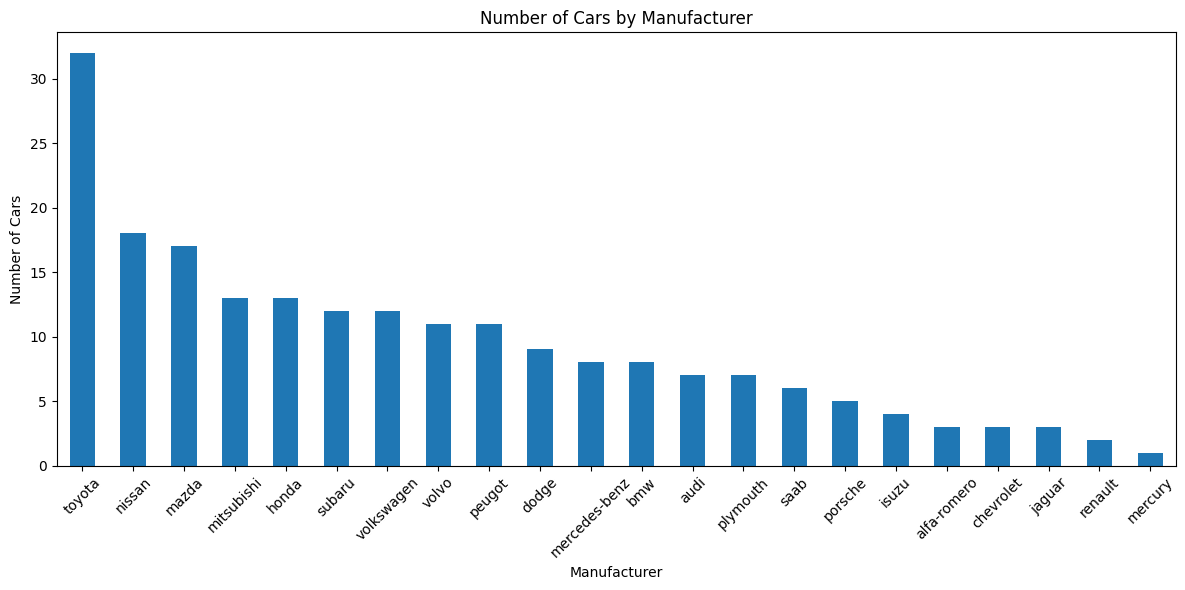


CAR PRICE STATISTICS:
Average Price: 13207.129353233831
Minimum Price: 5118.0
Maximum Price: 45400.0


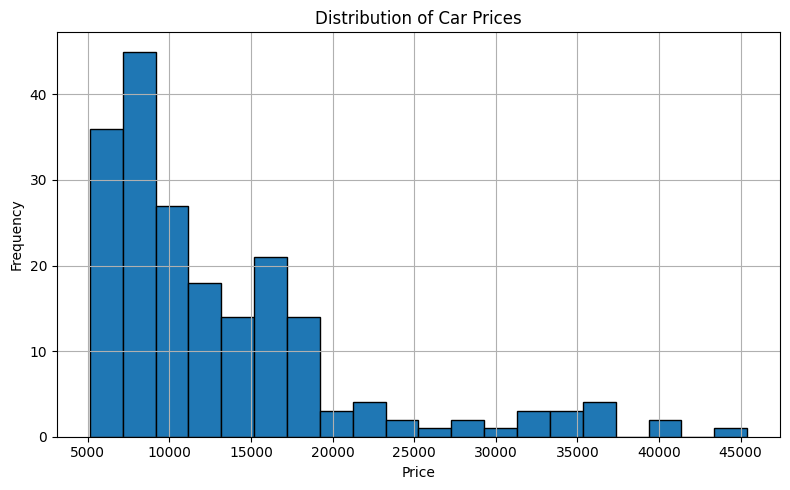


AVERAGE PRICE BY BODY STYLE:
body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14459.755319
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64

BODY STYLE WITH HIGHEST AVERAGE PRICE:
hardtop
HIGHEST AVERAGE PRICE:
22208.5

AVERAGE ENGINE SIZE BY FUEL TYPE:
fuel-type
diesel    135.700000
gas       125.956757
Name: engine-size, dtype: float64

TOP 10 MOST EXPENSIVE CARS:
              make   body-style fuel-type  engine-size  horsepower    price
74   mercedes-benz      hardtop       gas          304       184.0  45400.0
16             bmw        sedan       gas          209       182.0  41315.0
73   mercedes-benz        sedan       gas          308       184.0  40960.0
128        porsche  convertible       gas          194       207.0  37028.0
17             bmw        sedan       gas          209       182.0  36880.0
49          jaguar        sedan       gas          326       262.0  36000.0
48          jaguar        seda

In [4]:

# ================================================
# AUTOMOBILE DATASET - EXPLORATORY DATA ANALYSIS
# ================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io

# ================================================
# 2. LOAD DATASET
# ================================================

zip_path = "/automobile (3).zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    data = z.read("automobile/imports-85.data")

columns = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width",
    "height", "curb-weight", "engine-type", "num-of-cylinders",
    "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

df = pd.read_csv(
    io.BytesIO(data),
    names=columns,
    na_values="?"
)

print("DATASET LOADED SUCCESSFULLY")

# ================================================
# 3. DISPLAY FIRST 5 ROWS
# ================================================

print("\nFIRST 5 ROWS:")
print(df.head())

# ================================================
# 4. DISPLAY LAST 5 ROWS
# ================================================

print("\nLAST 5 ROWS:")
print(df.tail())

# ================================================
# 5. DATASET SHAPE
# ================================================

print("\nDATASET SHAPE:")
print(df.shape)

# ================================================
# 6. DATASET INFORMATION
# ================================================

print("\nDATASET INFORMATION:")
df.info()

# ================================================
# 7. STATISTICAL DESCRIPTION
# ================================================

print("\nSTATISTICAL DESCRIPTION:")
print(df.describe())

# ================================================
# 8. CHECK MISSING VALUES
# ================================================

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nCOLUMNS WITH MISSING VALUES:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ================================================
# 9. CHECK DUPLICATE ROWS
# ================================================

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

# ================================================
# 10. MANUFACTURER COUNTS
# ================================================

manufacturer_counts = df["make"].value_counts()

print("\nCARS BY MANUFACTURER:")
print(manufacturer_counts)

# ================================================
# 11. MANUFACTURER COUNT BAR CHART
# ================================================

plt.figure(figsize=(12, 6))

manufacturer_counts.plot(kind="bar")

plt.title("Number of Cars by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ================================================
# 12. AVERAGE, MINIMUM AND MAXIMUM CAR PRICE
# ================================================

prices = df["price"].dropna().to_numpy()

average_price = np.mean(prices)
minimum_price = np.min(prices)
maximum_price = np.max(prices)

print("\nCAR PRICE STATISTICS:")
print("Average Price:", average_price)
print("Minimum Price:", minimum_price)
print("Maximum Price:", maximum_price)

# ================================================
# 13. PRICE HISTOGRAM
# ================================================

plt.figure(figsize=(8, 5))

df["price"].dropna().hist(
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# ================================================
# 14. AVERAGE PRICE BY BODY STYLE
# ================================================

body_style_price = df.groupby("body-style")["price"].mean()

body_style_price = body_style_price.sort_values(
    ascending=False
)

print("\nAVERAGE PRICE BY BODY STYLE:")
print(body_style_price)

print("\nBODY STYLE WITH HIGHEST AVERAGE PRICE:")
print(body_style_price.idxmax())

print("HIGHEST AVERAGE PRICE:")
print(body_style_price.max())

# ================================================
# 15. AVERAGE ENGINE SIZE BY FUEL TYPE
# ================================================

engine_by_fuel = df.groupby("fuel-type")["engine-size"].mean()

print("\nAVERAGE ENGINE SIZE BY FUEL TYPE:")
print(engine_by_fuel)

# ================================================
# 16. TOP 10 MOST EXPENSIVE CARS
# ================================================

top_10_cars = df.sort_values(
    by="price",
    ascending=False
).head(10)

print("\nTOP 10 MOST EXPENSIVE CARS:")

print(
    top_10_cars[
        ["make", "body-style", "fuel-type",
         "engine-size", "horsepower", "price"]
    ]
)

# ================================================
# 17. PANDAS FILTERING
# CARS ABOVE AVERAGE PRICE
# ================================================

average = df["price"].mean()

expensive_cars = df[df["price"] > average]

print("\nCARS WITH PRICE ABOVE AVERAGE:")

print(
    expensive_cars[
        ["make", "body-style", "price"]
    ]
)

# ================================================
# 18. THREE OBSERVATIONS
# ================================================

print("\nTHREE OBSERVATIONS:")

print(
    "1. Toyota is the most frequently occurring "
    "manufacturer with 32 cars."
)

print(
    "2. The average car price is approximately "
    "13207.13, the minimum price is 5118, "
    "and the maximum price is 45400."
)

print(
    "3. Hardtop has the highest average price, "
    "while diesel cars have a higher average "
    "engine size than gas cars."
)

# ================================================
# 19. END OF ANALYSIS
# ================================================

print("\nAUTOMOBILE DATASET EDA COMPLETED SUCCESSFULLY!")
